## 300m rule: stats & vizualization

In [ ]:
CITY = "perugia"

In [62]:
import math
import os
from pathlib import Path
import geopandas as gpd
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.strtree import STRtree
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

import sys, os
from pathlib import Path
import h3

project_root = Path("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")
sys.path.insert(0, str(project_root))
os.chdir(project_root)

from config.config import (
    ROOT_PATH, CRS_METRIC, CRS_WGS,
    DB_PATH, GH_PORT, WALKING_DISTANCE, EUCLID_CUTOFF,
    connect_db, gdf_to_duckdb, load_table, gpkg_to_duckdb,
    get_city_cfg, get_output_paths,
)

os.chdir(ROOT_PATH)

cfg   = get_city_cfg(CITY)
src   = cfg["data_sources"]
paths = get_output_paths(CITY)

FIG_DIR = paths["fig_dir"]
os.makedirs(FIG_DIR, exist_ok=True)

print(f"City : {CITY}")
print(f"Figures: {FIG_DIR}")

TEAL  = "#1D9E75"
BLUE  = "#378ADD"
CORAL = "#F0997B"
LGRAY = "#D3D1C7"
AMBER = "#EF9F27"
TEXT  = "#2C2C2A"
SGRAY = "#888780"

plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.size":          11,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.6,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "figure.dpi":         150,
    "savefig.bbox":       "tight",
    "savefig.dpi":        150,
})


buildings_routed = gpd.read_file(paths["gpkg"], layer="buildings")
parks  = gpd.read_file(paths["gpkg"], layer="parks")
results = gpd.read_file(paths["gpkg"])
con = connect_db()
boundary_gdf = load_table(con, "raw", f"{CITY}_boundary")
boundary_wgs84 = boundary_gdf.to_crs(CRS_WGS).geometry.union_all()
print(boundary_gdf)
print(f"{len(results):,} address records loaded")
print(f"{len(parks):,} parks loaded")

park_area = (
    parks[["park_id", "geometry"]]
    .copy()
    .to_crs(CRS_METRIC)
    .assign(area_ha=lambda df: df.geometry.area / 10_000)
    [["park_id", "area_ha"]]
)

print(f"parks unique park_id: {parks['park_id'].nunique()} / {len(parks)}")

results = results.merge(
    park_area.rename(columns={"park_id": "nearest_park_id"}),
    on="nearest_park_id",
    how="left",
)

# Derive compliance columns used downstream
results["compliant_0ha"]   = results["within_300m"]
results["compliant_0.5ha"] = results["within_300m"] & (results["area_ha"] >= 0.5)
results["compliant_1.0ha"] = results["within_300m"] & (results["area_ha"] >= 1.0)

print(f"area_ha range: {results['area_ha'].min():.2f} – {results['area_ha'].max():.2f} ha")

total  = len(results)
avg = results['within_300m'].mean()
within  = results['within_300m'].sum()
no_park = results['nearest_park_id'].isna().sum()
routed = results['nearest_park_id'].notna().sum()
outside = routed - within        

print('300m PARK ACCESS INDICATOR — BOLOGNA')
print(f'STREET NUMBERS:')
print(f'Total civici:                  {total:>8,}')
print(f'Within 300m walk of park:      {within:>8,}  ({within/total*100:.1f}%)')
print(f'Outside 300m (park too far):   {outside:>8,}  ({outside/total*100:.1f}%)')
print(f'No park reachable (NaN):       {no_park:>8,}  ({no_park/total*100:.1f}%)')

print(f'\nWALK DISTANCE (routed buildings only):')
reachable = results[results['nearest_park_id'].notna()]
print(f'Median walk distance:          {results["walk_dist_m"].median():>8.0f} m')
print(f'Mean walk distance:            {results["walk_dist_m"].mean():>8.0f} m')
print(f'Max walk distance:             {results["walk_dist_m"].max():>8.0f} m')

print(f'\nPARKS REACHED:')
print(f'Unique parks accessed:         {results["nearest_park_id"].nunique():>8,}')


City : firenze
Figures: /Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index/figures/firenze


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'firenze_3_30_300_results.gpkg': 'buildings' (default), 'parks'. Specify layer parameter to avoid this warning.
  result = read_func(


   OBJECTID  COD_RIP  COD_REG  COD_PROV  COD_CM  COD_UTS  PRO_COM PRO_COM_T  \
0      4221        3        9        48     248      248    48017    048017   

    COMUNE  COMUNE_A  CC_UTS    Shape_Leng    Shape_Le_1    Shape_Area  \
0  Firenze      <NA>       1  52759.919248  52759.919248  1.021789e+08   

      city                                           geometry  
0  firenze  POLYGON ((683987.811 4855769.872, 684131.794 4...  
109,083 address records loaded
464 parks loaded
parks unique park_id: 464 / 464
area_ha range: 0.01 – 87.03 ha
300m PARK ACCESS INDICATOR — BOLOGNA
STREET NUMBERS:
Total civici:                   109,083
Within 300m walk of park:        53,033  (48.6%)
Outside 300m (park too far):      3,524  (3.2%)
No park reachable (NaN):         52,526  (48.2%)

WALK DISTANCE (routed buildings only):
Median walk distance:               179 m
Mean walk distance:                 179 m
Max walk distance:                 2358 m

PARKS REACHED:
Unique parks accessed:          

## fig01. park access by h3

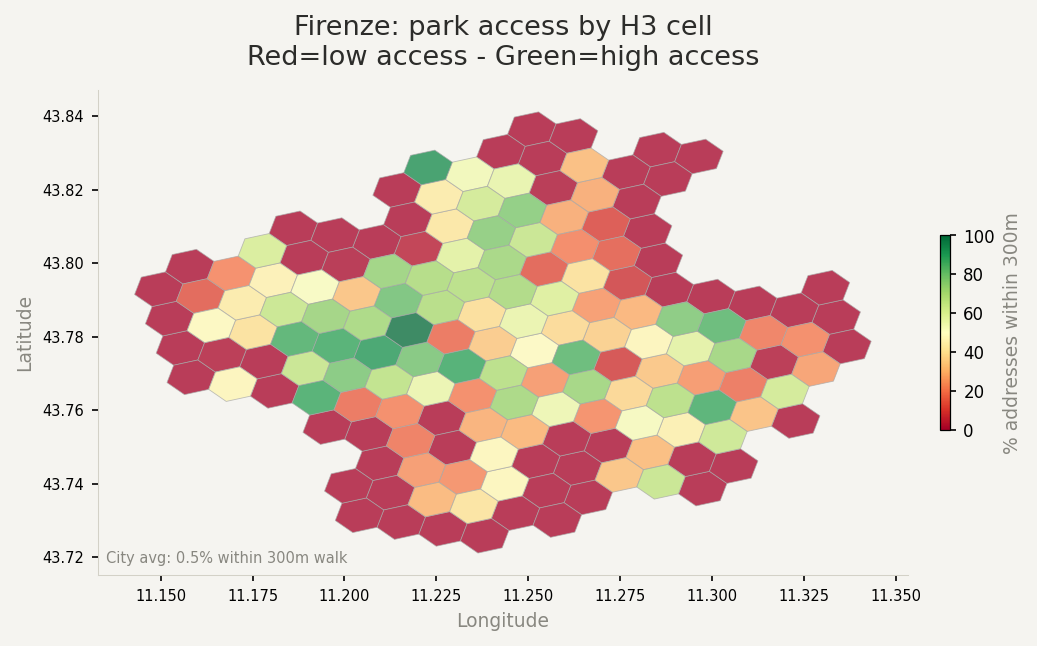

In [63]:
H3_RES = 8   # ~460m hex edge; tune: 7=~1.2km, 8=~460m, 9=~175m

results_wgs = results.to_crs(CRS_WGS)
results["h3_cell"] = results_wgs.geometry.apply(
    lambda geom: h3.latlng_to_cell(geom.centroid.y, geom.centroid.x, H3_RES)
)

h3_stats = (
    results.groupby("h3_cell")["within_300m"]
    .agg(total="count", within="sum")
    .assign(pct=lambda x: x["within"] / x["total"] * 100)
    .sort_values("pct", ascending=True)
    .reset_index()
)

# Build H3 polygon GeoDataFrame
def h3_to_polygon(cell):
    coords = h3.cell_to_boundary(cell)   # list of (lat, lng)
    return [[lng, lat] for lat, lng in coords]

h3_polygons = []
for _, row in h3_stats.iterrows():
    verts = h3_to_polygon(row["h3_cell"])
    h3_polygons.append({
        "h3_cell": row["h3_cell"],
        "pct": row["pct"],
        "total": row["total"],
        "geometry": __import__("shapely.geometry", fromlist=["Polygon"]).Polygon(verts),
    })

h3_gdf = gpd.GeoDataFrame(h3_polygons, crs=CRS_WGS)

# Colour map
norm  = Normalize(vmin=0, vmax=100)
cmap  = plt.cm.RdYlGn

lon_range = results["entrance_lon"].max() - results["entrance_lon"].min()
lat_range = results["entrance_lat"].max()  - results["entrance_lat"].min()
lat_mid   = results["entrance_lat"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))
fig_w, fig_h = 11, 11 / aspect

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")

# Draw H3 hexagons coloured by compliance %
h3_gdf.plot(
    column="pct", cmap="RdYlGn", linewidth=0.4,
    edgecolor="#AAAAAA", ax=ax, vmin=0, vmax=100,
    alpha=0.75, zorder=2,
)

# Colorbar
sm = ScalarMappable(cmap="RdYlGn", norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.4, pad=0.02, orientation="vertical")
cbar.set_label("% addresses within 300m", fontsize=9, color=SGRAY)
cbar.ax.tick_params(labelsize=8)

ax.set_aspect("equal")
ax.set_title(
    f"{CITY.title()}: park access by H3 cell\n"
    f"Red=low access - Green=high access",
    fontsize=13, fontweight="500", pad=12, color=TEXT,
)
ax.set_xlabel("Longitude", fontsize=9, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=9, color=SGRAY)
ax.tick_params(labelsize=7)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY); spine.set_linewidth(0.5)

ax.text(0.01, 0.02, f"City avg: {avg:.1f}% within 300m walk",
        transform=ax.transAxes, fontsize=7, color=SGRAY, ha="left", va="bottom")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig01_h3_walkability_map.png", dpi=180)
plt.show()

In [56]:
FIG_BG  = "#1a1a2e"
PAN_BG  = "#12122a"
LAND_BG = "#2e2e4a"
city_gdf = boundary_gdf.to_crs(CRS_WGS)
import osmnx as ox

# get bounds from city + some padding
minx, miny, maxx, maxy = city_gdf.total_bounds
pad = 0.05  # ~5km padding around the city
G = ox.graph_from_bbox(
    bbox=(maxy + pad, miny - pad, maxx + pad, minx - pad),
    network_type="drive",
    retain_all=True,
)
edges = ox.graph_to_gdfs(G, nodes=False)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor(FIG_BG)
ax.set_facecolor(PAN_BG)

# lock view FIRST
minx, miny, maxx, maxy = city_gdf.total_bounds
pad = 0.01
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)

# streets — much more visible color
edges.to_crs(CRS_WGS).plot(ax=ax, linewidth=0.4, color="#ffffff55", zorder=1)

# city boundary
city_gdf.boundary.plot(ax=ax, color="white", linewidth=1.0, alpha=0.6, zorder=2)

h3_gdf_clipped = gpd.clip(h3_gdf, city_gdf)

# hexagons
h3_gdf_clipped.plot(
    column="pct", cmap="RdYlGn", linewidth=0.3,
    edgecolor="#ffffff22", ax=ax, vmin=0, vmax=100,
    alpha=0.78, zorder=3,
)


ax.set_aspect("equal")
ax.axis("off")

ax.set_title(
    f"{CITY.title()}: park access by H3 cell",
    fontsize=14, fontweight="500", pad=12, color="white",
)

sm   = ScalarMappable(cmap="RdYlGn", norm=Normalize(vmin=0, vmax=100))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.35, pad=0.02, orientation="vertical")
cbar.set_label("% addresses within 300m", fontsize=9, color="white")
cbar.ax.yaxis.set_tick_params(color="white", labelcolor="white")
cbar.outline.set_edgecolor("white")

ax.text(0.01, 0.02, f"City avg: {avg:.1f}% within 300m walk",
        transform=ax.transAxes, fontsize=8, color="#aaaaaa", ha="left", va="bottom")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig02_h3_walkability_map.png", dpi=180, facecolor=FIG_BG)
plt.show()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/osmnx/_overpass.py:271: UserWarning: This area is 5,261 times your configured Overpass max query area size. It will automatically be divided up into multiple sub-queries accordingly. This may take a long time.
  multi_poly_proj = utils_geo._consolidate_subdivide_geometry(poly_proj)


KeyboardInterrupt: 

## 


## fig03. 300m by parksize
- sicne according to WHO park should be at least 0,5 ha 

Three address groups at each threshold:
- compliant  — within 300m of a park that meets the size requirement
- lost       — within 300m but their nearest park is smaller than threshold
- never      — never within 300m regardless of size (no park reachable)

"lost" is computed as: was within 300m at baseline, but the matched park is smaller than t ha.  It accumulates as threshold rises.

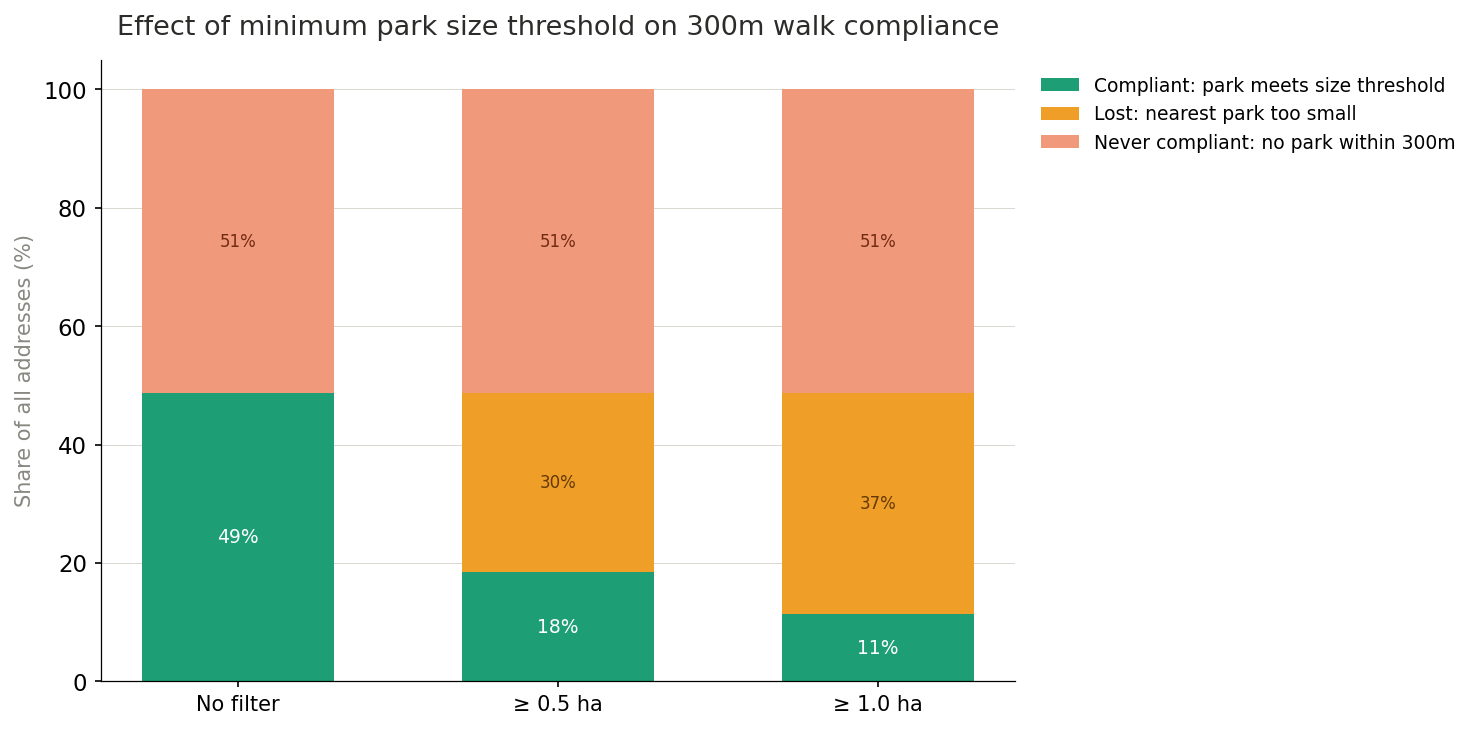

In [64]:
# First, compute the base metrics
within_300m = results["within_300m"]              
meets_05ha = results["compliant_0.5ha"]  # Has park within 300m AND ≥ 0.5ha
meets_10ha = results["compliant_1.0ha"]  # Has park within 300m AND ≥ 1.0ha

# For 0.5ha threshold
lost_distance_05 = within_300m & ~meets_05ha  # Within 300m but too small
lost_size_05 = (~within_300m) & results["compliant_0.5ha"]  # Beyond 300m but would qualify

# For 1.0ha threshold  
lost_distance_10 = within_300m & ~meets_10ha
lost_size_10 = (~within_300m) & results["compliant_0.5ha"]

# Build the dataframe
size_df = pd.DataFrame([
    {
        "threshold": 0,
        "c_pct":  within_300m.mean() * 100,  # All within 300m
        "l_pct":  0,
        "n_pct":  (~within_300m).mean() * 100,  # None within 300m
        "parks":  results["nearest_park_id"].nunique(),
    },
    {
        "threshold": 0.5,
        "c_pct":  meets_05ha.mean() * 100,
        "l_pct":  lost_distance_05.mean() * 100,  # Within 300m, too small
        "n_pct":  (~within_300m).mean() * 100,  # No park within 300m
        "parks":  results[results["area_ha"] >= 0.5]["nearest_park_id"].nunique(),
    },
    {
        "threshold": 1.0,
        "c_pct":  meets_10ha.mean() * 100,
        "l_pct":  lost_distance_10.mean() * 100,  # Within 300m, too small
        "n_pct":  (~within_300m).mean() * 100,  # No park within 300m
        "parks":  results[results["area_ha"] >= 1.0]["nearest_park_id"].nunique(),
    },
])

x       = size_df.index.to_numpy()
width   = 0.6
xlabels = ["No filter", "≥ 0.5 ha", "≥ 1.0 ha"]
#Stacked compliance bars
fig, ax_top = plt.subplots(figsize=(10, 5))

b1 = ax_top.bar(x, size_df.c_pct, width, color=TEAL,  label="Compliant: park meets size threshold", zorder=2)
b2 = ax_top.bar(x, size_df.l_pct, width, bottom=size_df.c_pct, color=AMBER, label="Lost: nearest park too small", zorder=2)
b3 = ax_top.bar(x, size_df.n_pct, width, bottom=size_df.c_pct + size_df.l_pct, color=CORAL, label="Never compliant: no park within 300m", zorder=2)

for i, row in size_df.iterrows():
    if row.c_pct > 5:
        ax_top.text(i, row.c_pct / 2, f"{row.c_pct:.0f}%",
            ha="center", va="center", fontsize=9, color="white", fontweight="500")
    if row.l_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct / 2, f"{row.l_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#633806")
    if row.n_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct + row.n_pct / 2, f"{row.n_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#712B13")
ax_top.set_xticks(x)
ax_top.set_xticklabels(xlabels, fontsize=10)
ax_top.set_ylabel("Share of all addresses (%)", fontsize=10, color=SGRAY)
ax_top.set_ylim(0, 105)
ax_top.set_title("Effect of minimum park size threshold on 300m walk compliance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax_top.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
ax_top.legend(fontsize=9, frameon=False, loc="upper left",
    bbox_to_anchor=(1.01, 1.0))

plt.tight_layout()
plt.savefig(f"figures/{CITY}/fig03_300m_by_parksize.png", bbox_inches="tight", dpi=150)
plt.show()

## fig04. number of parks surviving 0.5 and 1 ha threshold

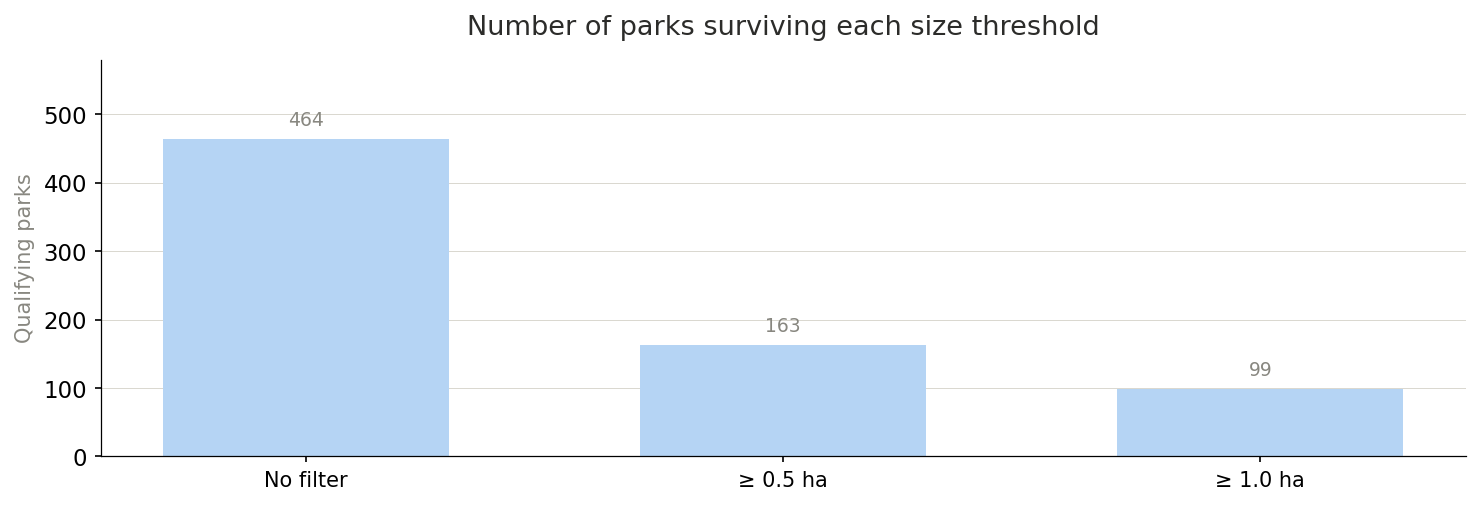

In [65]:
fig, ax_bot = plt.subplots(figsize=(10, 3.5))

ax_bot.bar(x, size_df.parks, width, color="#B5D4F4", zorder=2)
for i, row in size_df.iterrows():
    ax_bot.text(i, row.parks + size_df.parks.max() * 0.03,
        str(int(row.parks)), ha="center", va="bottom", fontsize=9, color=SGRAY)

ax_bot.set_xticks(x)
ax_bot.set_xticklabels(xlabels, fontsize=10)
ax_bot.set_ylabel("Qualifying parks", fontsize=10, color=SGRAY)
ax_bot.set_title("Number of parks surviving each size threshold",
    fontsize=13, fontweight="500", color=TEXT, pad=12)
ax_bot.set_ylim(0, size_df.parks.max() * 1.25)
ax_bot.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.tight_layout()
plt.savefig(f"figures/{CITY}/fig04_walkability_compliance_by_park_size.png", bbox_inches="tight", dpi=150)
plt.show()

## fig05. euclidean distance vs. walking distance

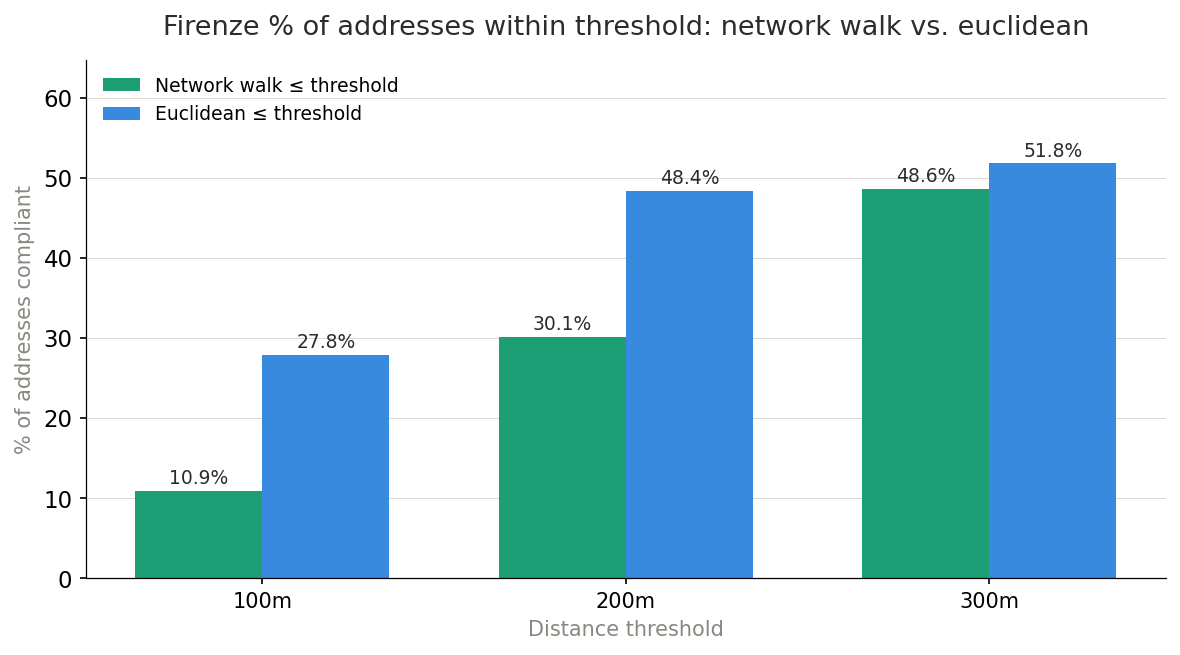

In [66]:
parks_metric = parks.to_crs(CRS_METRIC)
park_id_to_idx = {pid: i for i, pid in enumerate(parks_metric["park_id"])}

matched = results[results["entrance_lat"].notna()].copy().reset_index(drop=True)

# Use building geometry directly — no longitude/latitude columns exist
civico_metric = matched.to_crs(CRS_METRIC).reset_index(drop=True)

def dist_to_park_boundary(row_idx, park_id):
    if pd.isna(park_id):
        return np.nan
    pidx = park_id_to_idx.get(park_id)
    if pidx is None:
        return np.nan
    return civico_metric.geometry.iloc[row_idx].distance(
        parks_metric.geometry.iloc[pidx].boundary
    )

matched["euclid_dist_m"] = [
    dist_to_park_boundary(i, row["nearest_park_id"])
    for i, row in matched.iterrows()
]

matched_wgs = matched.to_crs(CRS_WGS)
matched["longitude"] = matched_wgs.geometry.x
matched["latitude"]  = matched_wgs.geometry.y

results_wgs = results.to_crs(CRS_WGS)
results["longitude"] = results_wgs.geometry.x
results["latitude"]  = results_wgs.geometry.y

w = 0.35

dist_thresholds = [100, 200, 300] 

# Calculate walk_pct_real and euclid_pct_real for EACH threshold
walk_pct_real = []
euclid_pct_real = []
x = []

for threshold in dist_thresholds:
    walk_pct = (results["walk_dist_m"] <= threshold).sum() / total * 100
    euclid_pct = (matched["euclid_dist_m"] <= threshold).sum()/ total  * 100
    walk_pct_real.append(walk_pct)
    euclid_pct_real.append(euclid_pct)

    
    x.append(dist_thresholds.index(threshold))  # or just use range(len(dist_thresholds))

# Convert to numpy arrays for easier plotting
walk_pct_real = np.array(walk_pct_real)
euclid_pct_real = np.array(euclid_pct_real)
x = np.arange(len(dist_thresholds))


fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bars, no secondary axis
b1 = ax.bar(x - w/2, walk_pct_real,   width=w, color=TEAL, label="Network walk ≤ threshold",  zorder=2, linewidth=0)
b2 = ax.bar(x + w/2, euclid_pct_real, width=w, color=BLUE, label="Euclidean ≤ threshold", zorder=2, linewidth=0)

# Value labels above bars
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, color=TEXT)



ax.set_xticks(x)
ax.set_xticklabels([f"{t}m" for t in dist_thresholds], fontsize=10)
ax.set_ylabel("% of addresses compliant", fontsize=10, color=SGRAY)
ax.set_xlabel("Distance threshold", fontsize=10, color=SGRAY)
ax.set_title(
    f"{CITY.title()} % of addresses within threshold: network walk vs. euclidean",
    fontsize=13, fontweight="500", pad=12, color=TEXT
)
ax.set_ylim(0, max(euclid_pct_real) * 1.25)
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

# clean single legend
ax.legend(handles=[b1, b2], fontsize=9, frameon=False,
    loc="upper left")

plt.tight_layout()
plt.savefig(f"figures/{CITY}/fig05_euclid_vs_walk.png", bbox_inches="tight", dpi=150)
plt.show()

## fig06. access gap map (300m compliance)

- Each dot = one civic address, plotted at its lon/lat.
- Teal  = within 300m walk of a park
- Coral = outside 300m (the access gap)


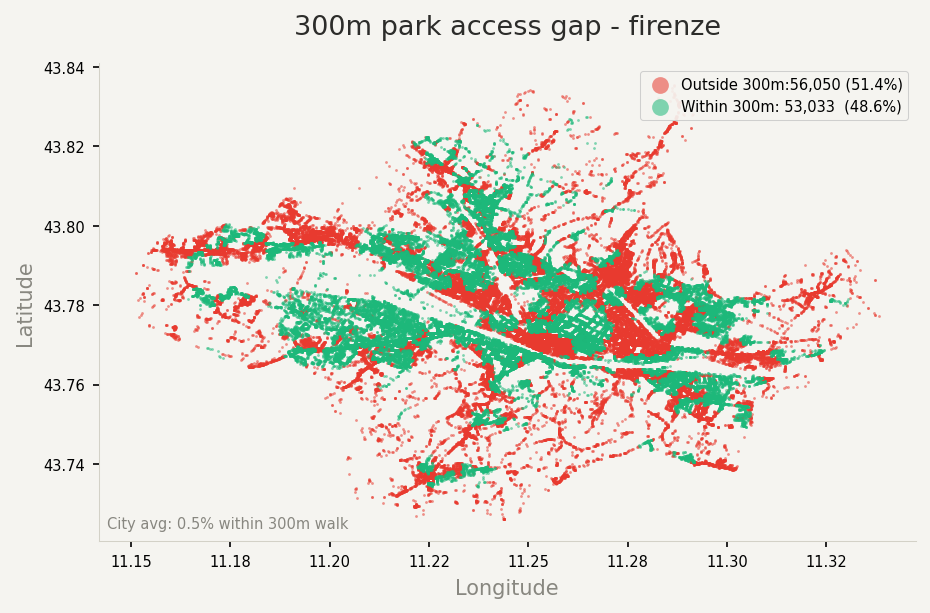

: 

In [ ]:
# Brighter colours for dot map
DOT_OUT = "#E83A2F"   # vivid red for outside (the problem)
DOT_IN  = "#1DB87A"   # vivid green for inside (the good)

inside  = results[results["within_300m"]]
outside = results[~results["within_300m"]]

lon_range = results["longitude"].max() - results["longitude"].min()
lat_range = results["latitude"].max()  - results["latitude"].min()
lat_mid   = results["latitude"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))
fig_w, fig_h = 10, 10 / aspect

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")

# Draw outside first (red), inside on top (green)
ax.scatter(outside["longitude"], outside["latitude"],
    s=1.8, color=DOT_OUT, alpha=0.55, linewidths=0,
    label=f"Outside 300m:{len(outside):,} ({len(outside)/total*100:.1f}%)",
    rasterized=True, zorder=2)
ax.scatter(inside["longitude"], inside["latitude"],
    s=1.8, color=DOT_IN,  alpha=0.55, linewidths=0,
    label=f"Within 300m: {len(inside):,}  ({len(inside)/total*100:.1f}%)",
    rasterized=True, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("Longitude", fontsize=10, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=10, color=SGRAY)
ax.set_title(f"300m park access gap - {CITY}",
    fontsize=13, fontweight="500", pad=14, color=TEXT)
ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.tick_params(labelsize=7)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY)
    spine.set_linewidth(0.5)

# Legend upper right, slightly inset
legend = ax.legend(
    fontsize=7, frameon=True, framealpha=0.92, loc="upper right",
    markerscale=6, handletextpad=0.4,
)
legend.get_frame().set_linewidth(0.5)
legend.get_frame().set_facecolor("#F5F4F0")

ax.text(0.01, 0.02, f"City avg: {avg:.1f}% within 300m walk",
    transform=ax.transAxes, fontsize=7, color=SGRAY, ha="left", va="bottom")

plt.tight_layout()
plt.savefig(f"figures/{CITY}/fig06_access_gap_map.png", dpi=200, bbox_inches="tight")
plt.show()